
# Railway Track Defect Detection Using Deep Learning

## 1. Introduction

Railway tracks are an important part of transportation infrastructure. Continuous usage, environmental conditions, and heavy loads can cause different types of defects in railway tracks.

Manual inspection can be time-consuming and may depend on human observation.

This project aims to develop a deep learning-based computer vision system to identify railway track defects from images.

The system will analyze railway images and learn visual patterns to classify them according to the available dataset categories.

## 2. Project Objectives

- Understand and explore the railway defect dataset.
- Perform data cleaning and preprocessing.
- Visualize railway track images.
- Analyze the distribution of defect categories.
- Develop a deep learning model using TensorFlow.
- Train and evaluate the model.
- Develop an image prediction API using FastAPI.
- Test and document the complete project.

## 3. Project Scope

The project focuses on image-based railway defect detection using computer vision and deep learning techniques.

The model's classification categories and prediction capabilities will be determined by the actual dataset.

## 4. Technology Stack

- Programming Language: Python
- Deep Learning: TensorFlow
- Data Manipulation: NumPy, Pandas
- Image Processing: OpenCV, Pillow
- Visualization: Matplotlib, Seaborn
- Machine Learning: Scikit-learn
- API Development: FastAPI
- Development Environment: Jupyter Notebook



# 1. Dataset Understanding and Exploration

##  Understanding the Dataset

In this section, we will explore the railway defect dataset to understand its structure and contents.

Before developing a deep learning model, it is important to understand how the dataset is organized.

We will identify the dataset location, available folders, image formats, and the total number of images.

This analysis will help us decide the appropriate data preprocessing and model development strategies.


In [2]:

# 2.2 Explore Dataset Folder Structure

import os
from pathlib import Path
from collections import Counter

# Find the project root directory
current_dir = Path.cwd()

if (current_dir / "dataset").exists():
    project_root = current_dir
elif (current_dir.parent / "dataset").exists():
    project_root = current_dir.parent
else:
    project_root = current_dir

# Define dataset directory
dataset_path = project_root / "dataset"

print("Project Root:", project_root)
print("Dataset Path:", dataset_path)

# Check whether dataset exists
if dataset_path.exists():

    print("\nDataset folder found successfully!")

    # Display main folders
    print("\nFolders inside the dataset:")

    for item in sorted(dataset_path.iterdir()):
        if item.is_dir():
            print("Folder:", item.name)
        else:
            print("File:", item.name)

    # Supported image formats
    image_extensions = {
        ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
    }

    # Collect all image files
    image_files = [
        file for file in dataset_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    # Count total images
    print("\nTotal Number of Images:", len(image_files))

    # Count image formats
    formats = Counter(
        file.suffix.lower() for file in image_files
    )

    print("\nImage Formats:")
    for extension, count in formats.items():
        print(extension, ":", count)

    # Count images by immediate subfolder
    folder_counts = Counter(
        file.relative_to(dataset_path).parts[0]
        if len(file.relative_to(dataset_path).parts) > 1
        else "Dataset Root"
        for file in image_files
    )

    print("\nImages in Each Main Folder:")
    for folder, count in folder_counts.items():
        print(folder, ":", count)

    # Display first 10 image paths
    print("\nFirst 10 Image Paths:")
    for file in image_files[:10]:
        print(file.relative_to(project_root))

else:
    print("\nDataset folder not found!")
    print("Please check your project folder location.")


Project Root: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION
Dataset Path: c:\Users\shrey\Downloads\RAILWAY_DEFECT_DETECTION\dataset

Dataset folder found successfully!

Folders inside the dataset:
Folder: processed
Folder: raw

Total Number of Images: 1017

Image Formats:
.jpg : 1015
.jpeg : 1
.png : 1

Images in Each Main Folder:
raw : 1017

First 10 Image Paths:
dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36247.jpg
dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36250.jpg
dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36253.jpg
dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36360.jpg
dataset\raw\RailwayDefectDetectionDatabase V2\RailwayDefectDetectionDatabase\Validation\Defective\2386_3_4_36361.jpg
dataset\raw\RailwayDefectDetectionDatabase V


## Inference

The dataset directory was successfully inspected using Python.

The folder structure, total number of images, available image formats, and image distribution across the main folders were examined.

This exploration provides an initial understanding of the dataset and helps identify the next steps required for image preprocessing and deep learning model development.

The actual dataset characteristics will be determined from the execution results above.


## 2. Dataset Image Visualization

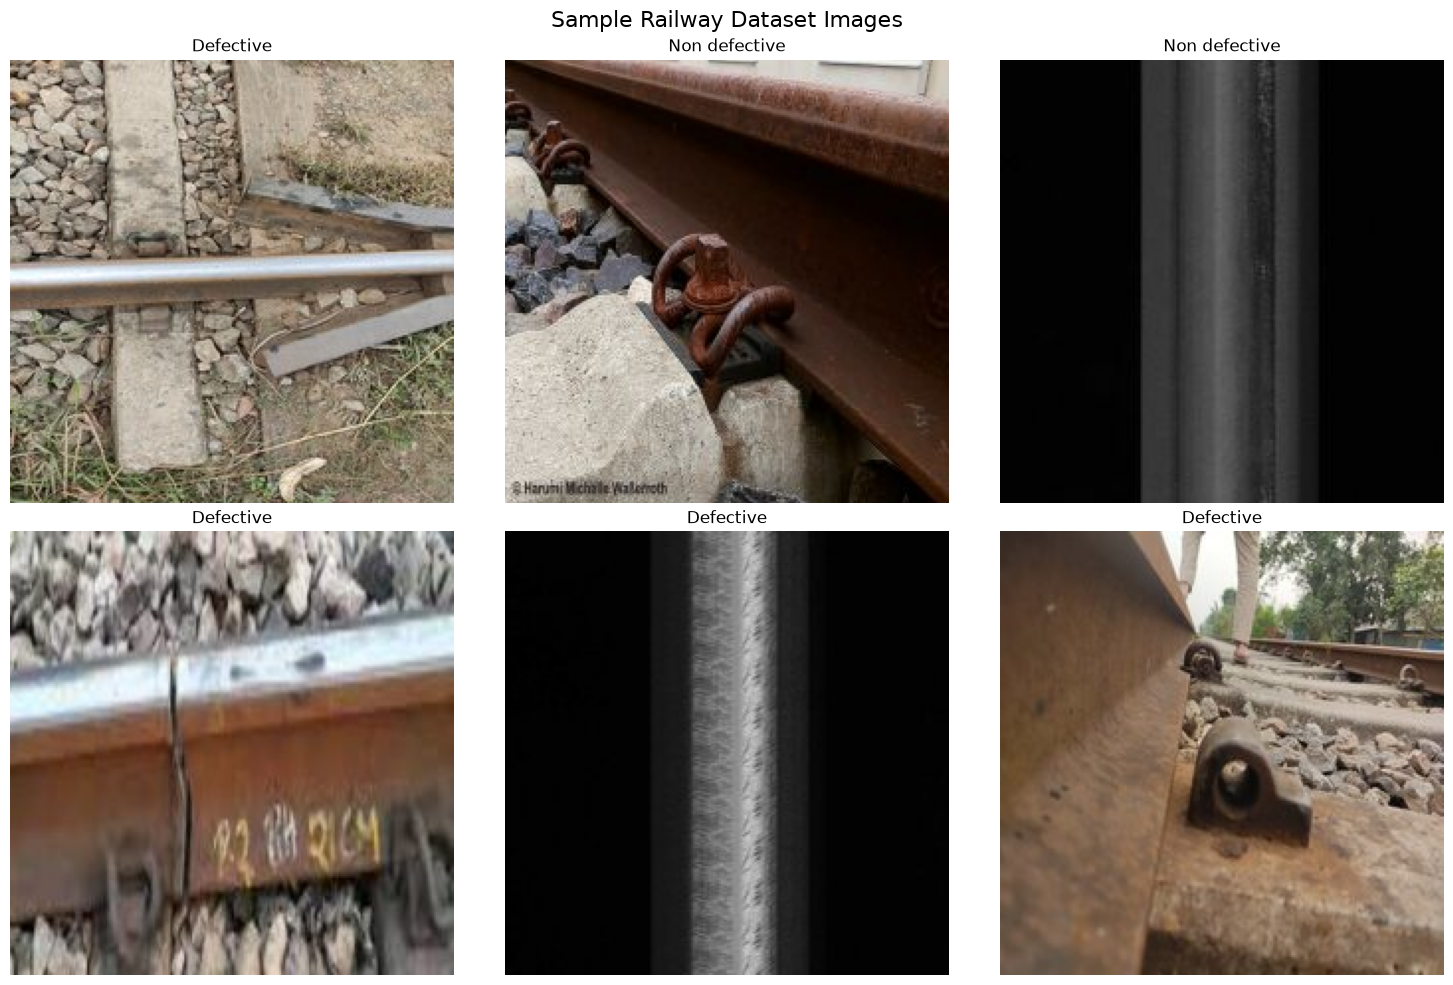

In [6]:



import matplotlib.pyplot as plt
from PIL import Image
import random

# Check available images
if len(image_files) > 0:

    # Select up to 6 sample images
    sample_images = random.sample(
        image_files,
        min(6, len(image_files))
    )

    # Create visualization
    plt.figure(figsize=(15, 10))

    for i, image_path in enumerate(sample_images):

        img = Image.open(image_path).convert("RGB")

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(image_path.parent.name)
        plt.axis("off")

    plt.suptitle(
        "Sample Railway Dataset Images",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

else:
    print("No images available for visualization.")



## Inference

Sample images from the railway defect dataset were visualized successfully.

Visual inspection helps us understand the appearance and variations of the railway images.

These observations will be useful for selecting suitable image preprocessing techniques before developing the deep learning model.


## 3. Image Dimension Analysis

In [5]:



# Import required libraries
import pandas as pd
from PIL import Image

image_dimensions = []

for image_path in image_files:

    try:
        with Image.open(image_path) as img:

            width, height = img.size

            image_dimensions.append({
                "Image": image_path.name,
                "Width": width,
                "Height": height,
                "Format": img.format
            })

    except Exception as e:
        print("Unable to read:", image_path.name, "|", e)

# Convert results into a DataFrame
dimensions_df = pd.DataFrame(image_dimensions)

# Display first 10 records
print("Image Dimension Details:")
display(dimensions_df.head(10))

# Statistical summary
print("\nDimension Statistics:")
display(dimensions_df[["Width", "Height"]].describe())

# Check unique image dimensions
print("\nUnique Image Dimensions:")
print(
    dimensions_df.groupby(
        ["Width", "Height"]
    ).size().sort_values(ascending=False)
)


Image Dimension Details:


,Image,Width,Height,Format
0,2386_3_4_36247.jpg,224,224,JPEG
1,2386_3_4_36250.jpg,224,224,JPEG
2,2386_3_4_36253.jpg,224,224,JPEG
3,2386_3_4_36360.jpg,224,224,JPEG
4,2386_3_4_36361.jpg,224,224,JPEG
5,2386_3_4_36362.jpg,224,224,JPEG
6,2386_3_4_36363.jpg,224,224,JPEG
7,2386_3_4_36364.jpg,224,224,JPEG
8,2386_3_4_36430.jpg,224,224,JPEG
9,2386_3_4_36433.jpg,224,224,JPEG



Dimension Statistics:


,Width,Height
count,1017.000000,1017.000000
mean,228.014749,224.530973
std,49.898310,11.714840
min,224.000000,87.000000
25%,224.000000,224.000000
50%,224.000000,224.000000
75%,224.000000,224.000000
max,1228.000000,422.000000



Unique Image Dimensions:
Width  Height
224    224       1008
282    87           1
429    306          1
510    418          1
533    422          1
642    252          1
679    177          1
786    189          1
1010   361          1
1228   344          1
dtype: int64



## Inference

The dimensions of the railway dataset images were analyzed successfully.

The width and height distributions provide information about the consistency of image sizes.

This analysis helps determine whether image resizing is required before feeding images into a deep learning model.


## 4. Final Dataset Analysis Validation

In [7]:
print("DATASET ANALYSIS SUMMARY")
print("------------------------")

print("Total images analyzed:", len(image_dimensions))

print("\nUnique image dimensions:")
print(dimensions_df)

print("\nDataset analysis completed successfully.")

DATASET ANALYSIS SUMMARY
------------------------
Total images analyzed: 1017

Unique image dimensions:
                        Image  Width  Height Format
0          2386_3_4_36247.jpg    224     224   JPEG
1          2386_3_4_36250.jpg    224     224   JPEG
2          2386_3_4_36253.jpg    224     224   JPEG
3          2386_3_4_36360.jpg    224     224   JPEG
4          2386_3_4_36361.jpg    224     224   JPEG
...                       ...    ...     ...    ...
1012  IMG_20201114_102253.jpg    224     224   JPEG
1013  IMG_20201114_102431.jpg    224     224   JPEG
1014  IMG_20201114_102710.jpg    224     224   JPEG
1015  IMG_20201114_102909.jpg    224     224   JPEG
1016  IMG_20201114_102945.jpg    224     224   JPEG

[1017 rows x 4 columns]

Dataset analysis completed successfully.


## Inference
The dataset analysis process was completed successfully.

The image dimensions were examined to understand
the variation in image sizes.

The analysis provides an initial understanding of
the dataset and prepares it for the next stage,
Image Preprocessing.